In [3]:
import glob
import os
import shutil
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# -----------------------------------------------------------------
# 1. Load pu_agg & Drop Leakage Columns
# -----------------------------------------------------------------
df = pd.read_parquet("../../data/processed/pu_agg.parquet")

# Drop leakage columns immediately if present
excluded_cols = [c for c in ["avg_total_amount", "avg_trip_distance"] if c in df.columns]
if excluded_cols:
    df = df.drop(columns=excluded_cols)

print("Columns available:", list(df.columns))

# -----------------------------------------------------------------
# 2. Key columns & Target Definition
# -----------------------------------------------------------------
target = "avg_trip_duration"  # Target: Average Trip Duration (seconds)
location_col = "location_id"
hour_col = "hour"
date_col = "date"

closure_cols = [
    c
    for c in df.columns
    if "construction" in c.lower()
]
print(f"Construction closure feature(s): {closure_cols}")

# -----------------------------------------------------------------
# 3. Clean Zero/Missing Duration Records & Sort Chronologically
# -----------------------------------------------------------------
df = df[df[target] > 0].copy()

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(by=[date_col, hour_col]).reset_index(drop=True)
df["day_of_week"] = df[date_col].dt.dayofweek

# -----------------------------------------------------------------
# 4. Cyclic time features
# -----------------------------------------------------------------
df["hour_sin"] = np.sin(2 * np.pi * df[hour_col] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df[hour_col] / 24.0)
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7.0)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7.0)

# -----------------------------------------------------------------
# 5. Features Definition & Leakage Assertion Check
# -----------------------------------------------------------------
numeric_features = [
    "ride_count",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
] + closure_cols
categorical_features = [location_col, "taxi_type"]
all_features = numeric_features + categorical_features

# Verification assertion: Ensure no leakage features are present
assert (
    "avg_total_amount" not in all_features
), "ERROR: Target leakage variable 'avg_total_amount' detected in feature set!"

keep_cols = all_features + [target, date_col]
model_df = df[keep_cols].dropna().reset_index(drop=True)

# -----------------------------------------------------------------
# 6. Train/Test split: Train = 2025, Test = 2026 Jan-May
# -----------------------------------------------------------------
train_df = model_df[model_df[date_col].dt.year == 2025].reset_index(
    drop=True
)
test_df = model_df[
    (model_df[date_col].dt.year == 2026) & (model_df[date_col].dt.month <= 5)
].reset_index(drop=True)

print(
    f"\nTrain: {train_df[date_col].min().date()} to {train_df[date_col].max().date()}  ({len(train_df):,} rows)"
)
print(
    f"Test:  {test_df[date_col].min().date()} to {test_df[date_col].max().date()}  ({len(test_df):,} rows)"
)
print(
    f"Mean avg_trip_duration — train: {train_df[target].mean():.2f}  |  test: {test_df[target].mean():.2f}"
)

X_train, y_train = train_df[all_features], train_df[target]
X_test, y_test = test_df[all_features], test_df[target]

# -----------------------------------------------------------------
# 7. Linear model pipeline (one-hot encodes categoricals)
# -----------------------------------------------------------------
lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat_ohe",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        )
    ],
    remainder="passthrough",
)
lr_pipeline = Pipeline(
    [("preprocess", lr_preprocessor), ("model", LinearRegression())]
)

# -----------------------------------------------------------------
# 8. Log-transform the target variable: log1p = log(y + 1)
# -----------------------------------------------------------------
y_train_log = np.log1p(y_train)

print("\nTraining Linear Regression (Log Target)...")
lr_pipeline.fit(X_train, y_train_log)

print("Training Random Forest (Log Target)...")
rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=10,
    max_samples=0.5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
)

X_train_rf = X_train.copy()
X_test_rf = X_test.copy()
for c in categorical_features:
    X_train_rf[c] = X_train_rf[c].astype("category").cat.codes
    X_test_rf[c] = X_test_rf[c].astype("category").cat.codes

rf_model.fit(X_train_rf, y_train_log)

# -----------------------------------------------------------------
# 9. Predict and Inverse-Transform: expm1 = exp(pred) - 1
# -----------------------------------------------------------------
lr_preds_log = lr_pipeline.predict(X_test)
rf_preds_log = rf_model.predict(X_test_rf)

lr_preds = np.clip(np.expm1(lr_preds_log), 0, None)
rf_preds = np.clip(np.expm1(rf_preds_log), 0, None)


def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(
        f"\n{name} (Log Transformed Target)\n  MAE:  {mae:.3f}\n  RMSE:"
        f" {rmse:.3f}"
    )
    return {"model": name, "MAE": mae, "RMSE": rmse}


results_df = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, lr_preds),
    evaluate_model("Random Forest", y_test, rf_preds),
])
print("\nSummary:")
print(results_df)

Columns available: ['date', 'hour', 'location_id', 'taxi_type', 'ride_count', 'avg_trip_duration', 'construction_count']
Construction closure feature(s): ['construction_count']

Train: 2025-01-01 to 2025-12-31  (2,171,748 rows)
Test:  2026-01-01 to 2026-05-31  (905,720 rows)
Mean avg_trip_duration — train: 1194.47  |  test: 1272.96

Training Linear Regression (Log Target)...
Training Random Forest (Log Target)...

Linear Regression (Log Transformed Target)
  MAE:  382.416
  RMSE: 720.235

Random Forest (Log Transformed Target)
  MAE:  338.789
  RMSE: 672.020

Summary:
               model         MAE        RMSE
0  Linear Regression  382.416462  720.235031
1      Random Forest  338.789011  672.019789


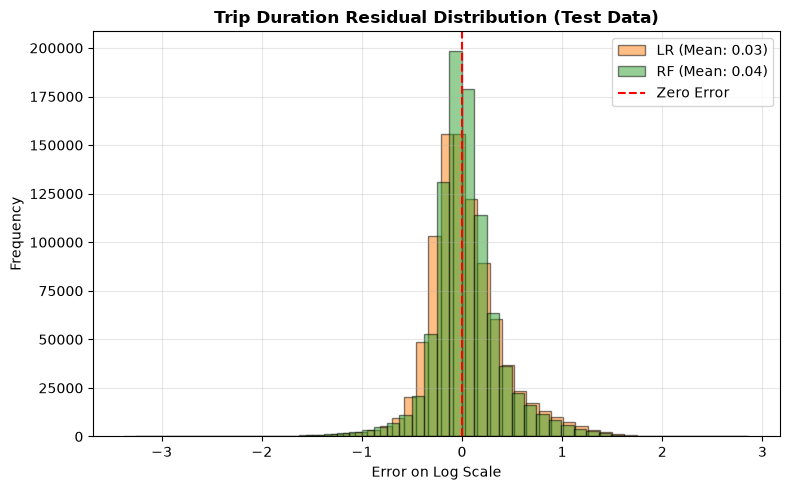

In [4]:
# -----------------------------------------------------------------
# 10. Distribution of Errors (Log Scale Residuals Only)
# -----------------------------------------------------------------
lr_log_res = np.log1p(y_test) - lr_preds_log
rf_log_res = np.log1p(y_test) - rf_preds_log

plt.figure(figsize=(8, 5))
    
plt.hist(
    lr_log_res,
    bins=50,
    alpha=0.5,
    label=f"LR (Mean: {lr_log_res.mean():.2f})",
    color="tab:orange",
    edgecolor="black",
)
plt.hist(
    rf_log_res,
    bins=50,
    alpha=0.5,
    label=f"RF (Mean: {rf_log_res.mean():.2f})",
    color="tab:green",
    edgecolor="black",
)
plt.axvline(
    0, color="red", linestyle="--", linewidth=1.5, label="Zero Error"
)

plt.xlabel("Error on Log Scale")
plt.ylabel("Frequency")
plt.title(
    "Trip Duration Residual Distribution (Test Data)",
    fontsize=12,
    fontweight="bold",
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# -----------------------------------------------------------------
# Extract Construction Feature Coefficients & Impact
# -----------------------------------------------------------------
# 1. Get feature names from the OneHotEncoder transformer
ohe_feature_names = lr_pipeline.named_steps["preprocess"] \
    .named_transformers_["cat_ohe"] \
    .get_feature_names_out(categorical_features)

feature_names = list(ohe_feature_names) + numeric_features
coefficients = lr_pipeline.named_steps["model"].coef_

# Create coefficient lookup DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coef_Log": coefficients
})

# 2. Filter for construction features
construction_coefs = coef_df[coef_df["Feature"].str.contains("construction", case=False)].copy()

# 3. Calculate percentage change: % Change = (exp(coef) - 1) * 100
construction_coefs["Percent_Impact"] = (np.expm1(construction_coefs["Coef_Log"])) * 100

# 4. Calculate approximate seconds added based on baseline trip duration
baseline_duration = train_df[target].mean()
construction_coefs["Approx_Seconds_Added"] = baseline_duration * (np.expm1(construction_coefs["Coef_Log"]))

print(f"\nBaseline Average Trip Duration (Train): {baseline_duration:.2f} seconds")
print("\n--- Construction Impact on Average Trip Duration ---")
print(construction_coefs.to_string(index=False))


Baseline Average Trip Duration (Train): 1194.47 seconds

--- Construction Impact on Average Trip Duration ---
           Feature  Coef_Log  Percent_Impact  Approx_Seconds_Added
construction_count   0.00014        0.013967              0.166835
